# AKLT chains as quantum wires
**Preliminary QuTiP notebook** · Can symmetry protect an edge qubit, and what does an ideal measurement step do to it?

We reproduce two results from [Pollmann et al., Phys. Rev. B 85, 075125 (2012)](https://doi.org/10.1103/PhysRevB.85.075125): the odd/even edge-spin distinction (Sec. III A) and the spin-2 path to a product state (Fig. 3). We then use the spin-1 tensors from Sec. III C for a separate two-site wire benchmark.

Run the cells in order with Python 3, QuTiP 5, NumPy and Matplotlib. To install them in a fresh Jupyter kernel, run `%pip install "qutip>=5,<6" numpy matplotlib`.

Extract the project ZIP and open this notebook beside the `modules/` folder.

In [1]:
from modules import *
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from itertools import product

## Chain models
Each subclass supplies one matrix per physical basis state of a repeating site. The dictionary keys label the basis and the matrices act on the virtual bond. The base class computes a transfer spectrum for any such model. Spin 2 provides the topologically trivial control.

## 1. What happens to an isolated edge?
An open spin-$S$ AKLT chain leaves an effective spin $s=S/2$ at either end. We model one end directly. The perturbation $H_{\rm edge}=D s_z^2$ respects time reversal because reversing $s_z$ leaves its square unchanged. Compare its energies at $D=1$ in arbitrary units. Section III A predicts a Kramers pair for the half-integer edge. An integer edge can acquire a unique ground state.

In [2]:
spin1 = Spin1AKLT()
spin2 = Spin2AKLTPath(t=1)
for chain in (spin1, spin2):
    # At the AKLT endpoints the isolated edge spin is half the bulk spin.
    s = chain.bulk_spin / 2
    edge_z = qt.jmat(s, "z")
    energies = (edge_z ** 2).eigenenergies()
    print(f"Bulk S={chain.bulk_spin}, edge s={s:g}: energies {energies}")

Bulk S=1, edge s=0.5: energies [0.25 0.25]
Bulk S=2, edge s=1: energies [0. 1. 1.]


The spin-1 chain retains a doublet. On the spin-2 chain the $m_z=0$ edge state is uniquely lowest. This calculation concerns a single isolated edge. In a finite open chain the two ends can interact.

## 2. Reproduce Fig. 3 for the spin-2 chain
The authors interpolate between the tensor for $|m_z=0\rangle$ on every site ($t=0$) and the spin-2 AKLT tensors ($t=1$). The five matrices in `modules/aklt.py` are Eq. (16), one for each physical measurement outcome $m$. Eq. (15) adds the product-state contribution only to the $m=0$ tensor.

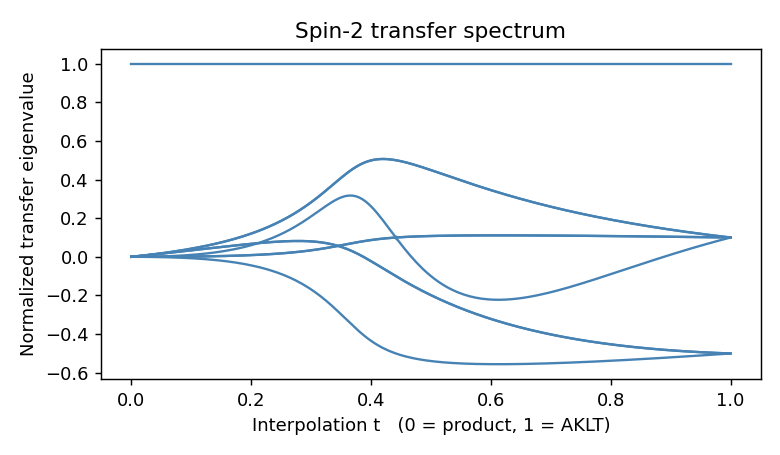

Largest subleading magnitude on the grid: 0.55555


In [3]:
t_grid = np.linspace(0, 1, 201)
spectra = np.array([Spin2AKLTPath(t).transfer_spectrum() for t in t_grid])
second_largest = np.sort(abs(spectra), axis=1)[:, -2]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(t_grid, spectra, color="steelblue", linewidth=1.3)
ax.set(xlabel="Interpolation t   (0 = product, 1 = AKLT)",
       ylabel="Normalized transfer eigenvalue", title="Spin-2 transfer spectrum")
fig.tight_layout()
plt.show()

print(f"Largest subleading magnitude on the grid: {second_largest.max():.5f}")
assert np.allclose(spectra[0], [0] * 8 + [1])
assert np.allclose(spectra[-1], [-0.5] * 3 + [0.1] * 5 + [1])
assert np.all(second_largest < 1)

Read the separation from $|\lambda|=1$. The leading eigenvalue is normalized to one. The next-largest magnitude sets the bulk correlation length $\xi=-1/\ln|\lambda_2|$ in sites. Our grid reproduces the finite separation seen in Fig. 3. The authors use this path and a parent-Hamiltonian argument to connect spin 2 smoothly to a product state. These eigenvalues describe bulk correlations. Wire fidelity requires a separate measurement calculation.

## 3. Project benchmark: transmit half a Bell pair through two spin-1 sites
At the spin-1 AKLT point, measuring in the Cartesian basis $x,y,z$ acts on the virtual qubit by a known Pauli matrix (Sec. III C). Use the normalized measurement operators $A_a=\sigma_a/\sqrt{3}$, so $\sum_a A_a^\dagger A_a=I$. The scalar fixes the outcome probabilities.

Keep the first half of $|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt2$ as a reference. If the two outcomes are $a$ then $b$, the logical operation is proportional to $P_bP_a$. Undo that product and average the Bell overlap over all nine records. This is a wire calculation motivated by the paper, with ideal encoding, readout and correction. For the computational-wire result see [Else et al., Phys. Rev. Lett. 108, 240505 (2012)](https://doi.org/10.1103/PhysRevLett.108.240505).

In [4]:
def two_site_bell_test(chain, correction):
    """Two measured sites in the chain's tensor basis, with a qubit bond."""
    steps = chain.tensors()
    identity = qt.qeye(2)
    if any(A.shape != (2, 2) for A in steps.values()):
        raise ValueError("This benchmark requires a two-dimensional virtual bond")
    if not np.allclose(sum(A.dag() * A for A in steps.values()).full(), np.eye(2)):
        raise ValueError("Measurement operators must sum to identity in A†A")

    bell = qt.bell_state("00")
    probability = raw = corrected = 0.0
    for first, second in product(steps, repeat=2):
        branch = qt.tensor(identity, steps[second] * steps[first]) * bell
        output = qt.tensor(identity, correction(first, second)) * branch
        # Branches carry their probabilities, so these are weighted overlaps.
        probability += branch.norm() ** 2
        raw += abs(bell.overlap(branch)) ** 2
        corrected += abs(bell.overlap(output)) ** 2
    return probability, raw, corrected

In [5]:
# The decoder belongs to this protocol and uses only recorded outcomes.
pauli = {"x": qt.sigmax(), "y": qt.sigmay(), "z": qt.sigmaz()}

def aklt_correction(first, second):
    return (pauli[second] * pauli[first]).dag()

probability, raw, corrected = two_site_bell_test(spin1, aklt_correction)
print(f"Total probability:                {probability:.6f}")
print(f"Bell fidelity without correction: {raw:.6f}")
print(f"Bell fidelity with correction:    {corrected:.6f}")
assert np.allclose([probability, raw, corrected], [1, 1/3, 1])

Total probability:                1.000000
Bell fidelity without correction: 0.333333
Bell fidelity with correction:    1.000000


**Interpretation.** Without the record, only the three equal-outcome pairs return the original Bell state. With the record, all nine pairs recover it. The unit corrected fidelity gives a baseline for testing other candidate wires. Spin 2 serves here as a control for phase protection. Assigning it a wire fidelity would require specifying an encoding, measurement basis and decoder for its three-dimensional virtual edge.

**Adding another wire.** Implement `tensors()` on a new subclass to reuse the transfer-spectrum calculation. To use the two-site Bell test, express its normalized qubit-bond tensors in the intended measurement basis and pass the corresponding correction function. A higher-dimensional bond needs an explicit qubit encoding and decoder.